# Detecting Parkinson’s Disease Using Acoustic Characteristics

### Which acoustic characteristics are most useful for distinguishing Parkinson’s disease from healthy controls, and which machine learning approach best captures these differences?

**Goal:** Compare SVM, Random Forest, and k-Nearest Neighbours for PD versus healthy-control classification, and investigate informative acoustic features.


## 1. Setup
Import the required libraries and set a fixed random seed. Use a Python environment with the project dependencies and select that environment as the notebook kernel.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
)

# Using the same seed for reproducible experiments.
SEED = 42
np.random.seed(SEED)

# Change this path if the project is moved to another computer.
DATA_FOLDER = "/Users/mominah/Desktop/COMPSCI 4AL3/Project/pd-speech-detection/db"
DATA_FILE = os.path.join(DATA_FOLDER, "segment_features.csv")

# Acoustic measurements used as model inputs.
FEATURE_COLUMNS = [
    "CPPS",
    "HNR",
    "Shimmer (local)",
    "Shimmer (local_dB)",
    "LTAS Slope",
    "LTAS Tilt",
]
TARGET_COLUMN = "PD"                 # 0 = healthy control, 1 = Parkinson's disease
GROUP_COLUMN = "participant_id"      # Keeps each participant within one fold.

print("Setup ready. Python:", sys.version.split()[0])
print("Random seed:", SEED)


Setup ready. Python: 3.14.2
Random seed: 42


## 2. Load the extracted features
Load `segment_features.csv` 
Display the first few rows, column names, data types, and shape. These are saved acoustic measurements; rerunning Praat is not required.



In [2]:
# Loading the previously extracted acoustic features.
df = pd.read_csv(DATA_FILE)

# Checking that the expected columns are present.
required_columns = [GROUP_COLUMN, "task", "segment_id", TARGET_COLUMN] + FEATURE_COLUMNS
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Inspecting the data before cleaning or standardization.
print("Loaded:", DATA_FILE)
print("Shape (segments, columns):", df.shape)
print("Unique participants:", df[GROUP_COLUMN].nunique())
print("Columns:", df.columns.tolist())
display(df.head())


print("\nSegments by class (0 = HC, 1 = PD):")
print(df[TARGET_COLUMN].value_counts().sort_index())


Loaded: /Users/mominah/Desktop/COMPSCI 4AL3/Project/pd-speech-detection/db/segment_features.csv
Shape (segments, columns): (1013, 10)
Unique participants: 37
Columns: ['participant_id', 'task', 'segment_id', 'PD', 'CPPS', 'HNR', 'Shimmer (local)', 'Shimmer (local_dB)', 'LTAS Slope', 'LTAS Tilt']


,participant_id,task,segment_id,PD,CPPS,HNR,Shimmer (local),Shimmer (local_dB),LTAS Slope,LTAS Tilt
0,0,RT,0,0,4.601844,5.988,0.186764,1.611423,-31.491537,-4.685515
1,0,RT,1,0,6.634655,11.073,0.117000,1.441925,-25.671000,-7.142106
2,0,RT,2,0,9.650368,13.924,0.108757,1.074178,-22.987132,-5.577274
3,0,RT,3,0,9.555163,13.267,0.098861,0.994412,-21.863595,-6.280987
4,0,RT,4,0,9.425526,12.861,0.107581,1.050289,-21.375866,-7.686769



Segments by class (0 = HC, 1 = PD):
PD
0    595
1    418
Name: count, dtype: int64


## 3. Check and clean the data
Keep `df` unchanged and create an unscaled copy named `clean_df`.

- Check identifiers, labels, recording tasks, and label consistency within each participant.
- Remove rows with missing, non-numeric, or infinite acoustic measurements; retain valid zeros and negative values.
- Remove exact duplicate records. Stop for review if a segment identifier has conflicting records.
- Summarize class balance, recording availability, and feature distributions.

Outliers are retained for inspection. Do not use full-dataset plots to select features or tune models. Scaling and any learned preprocessing belong inside the training folds.

**Feature units:** CPPS, HNR, local shimmer in dB, and the two LTAS band contrasts are in dB. Local shimmer is stored as a fraction (multiply by 100 only when reporting percentages). The column labelled LTAS tilt is a band-energy contrast on a trend fitted over 600–4,000 Hz.


In [3]:
def preprocess(data):
    # Working on a copy so that the original DataFrame is preserved.
    clean = data.copy()
    segment_columns = [GROUP_COLUMN, "task", "segment_id"]

    # Missing or invalid identifiers/labels require investigation, not guessing.
    for column in [GROUP_COLUMN, "segment_id"]:
        values = pd.to_numeric(clean[column], errors="coerce")
        valid = np.isfinite(values) & (values >= 0) & (values % 1 == 0)
        if not valid.all():
            raise ValueError(f"Invalid or missing identifiers in {column}.")
        clean.loc[:, column] = values.astype(int)

    if not clean[TARGET_COLUMN].isin([0, 1]).all():
        raise ValueError("PD labels must be 0 (HC) or 1 (PD), with no missing labels.")
    if not clean["task"].isin(["RT", "SD"]).all():
        raise ValueError("Recording tasks must be RT or SD, with no missing tasks.")
    clean.loc[:, TARGET_COLUMN] = clean[TARGET_COLUMN].astype(int)

    # Every participant must have the same diagnosis across all their segments.
    labels_per_participant = clean.groupby(GROUP_COLUMN)[TARGET_COLUMN].nunique()
    if (labels_per_participant > 1).any():
        raise ValueError("A participant has conflicting PD labels; inspect the source data.")

    # Converting unexpected non-numeric feature values to NaN for detection.
    clean.loc[:, FEATURE_COLUMNS] = clean[FEATURE_COLUMNS].apply(pd.to_numeric, errors="coerce")
    clean = clean.astype({feature: float for feature in FEATURE_COLUMNS})
    invalid_counts = (~np.isfinite(clean[FEATURE_COLUMNS])).sum()
    print("Invalid measurements per feature:")
    display(invalid_counts.rename("invalid_count").to_frame())

    # Removing exact copies, while flagging conflicting records for the same segment.
    before_duplicates = len(clean)
    clean = clean.drop_duplicates().copy()
    duplicate_count = before_duplicates - len(clean)
    if clean.duplicated(subset=segment_columns).any():
        raise ValueError("Conflicting records share a segment ID; inspect before proceeding.")

    # Removing rows with invalid features using one shared mask for all columns.
    valid_rows = np.isfinite(clean[FEATURE_COLUMNS]).all(axis=1)
    invalid_count = int((~valid_rows).sum())
    clean = clean.loc[valid_rows].reset_index(drop=True)
    if clean.empty:
        raise ValueError("No valid segments remain after cleaning.")
    if clean[TARGET_COLUMN].nunique() != 2:
        raise ValueError("Both PD and HC must remain after cleaning.")

    print("Original segments:", len(data))
    print("Removed exact duplicate records:", duplicate_count)
    print("Removed segments with invalid features:", invalid_count)
    print("Remaining segments:", len(clean))
    print("Remaining participants:", clean[GROUP_COLUMN].nunique())
    return clean


clean_df = preprocess(df)


Invalid measurements per feature:


,invalid_count
CPPS,0
HNR,0
Shimmer (local),0
Shimmer (local_dB),0
LTAS Slope,0
LTAS Tilt,0


Original segments: 1013
Removed exact duplicate records: 0
Removed segments with invalid features: 0
Remaining segments: 1013
Remaining participants: 37


In [4]:
# Summarizing class balance at segment and participant levels.
class_names = {0: "HC", 1: "PD"}
participants = clean_df[[GROUP_COLUMN, TARGET_COLUMN]].drop_duplicates()
class_summary = pd.DataFrame({
    "participants": participants[TARGET_COLUMN].value_counts(),
    "segments": clean_df[TARGET_COLUMN].value_counts(),
}).sort_index().rename(index=class_names)
class_summary.loc[:, "segment_percent"] = (100 * class_summary["segments"] / len(clean_df)).round(1)
display(class_summary)

# A missing task is not a missing feature value; keep the participant's available data.
print("Segments per participant and recording task:")
recording_counts = pd.crosstab(clean_df[GROUP_COLUMN], clean_df["task"])
recording_counts = recording_counts.reindex(columns=["RT", "SD"], fill_value=0)
display(recording_counts)
print("Participants without retained segments for a task:")
display(recording_counts.eq(0).sum().rename("participant_count").to_frame())

print("Acoustic feature summary (unscaled; outliers retained):")
display(clean_df[FEATURE_COLUMNS].describe().T)


,participants,segments,segment_percent
PD,,,
HC,21,595,58.7
PD,16,418,41.3


Segments per participant and recording task:


task,RT,SD
participant_id,,
0,15,12
1,16,11
2,15,19
3,14,15
4,12,14
5,11,18
6,18,13
7,14,21
8,14,13


Participants without retained segments for a task:


,participant_count
task,
RT,0
SD,1


Acoustic feature summary (unscaled; outliers retained):


,count,mean,std,min,25%,50%,75%,max
CPPS,1013.0,8.142426,1.856037,4.257645,6.663731,8.179473,9.559716,13.013291
HNR,1013.0,12.214759,3.144562,2.381000,10.767000,12.817000,14.193000,20.527000
Shimmer (local),1013.0,0.107747,0.038716,0.036569,0.083812,0.096813,0.117933,0.258078
Shimmer (local_dB),1013.0,1.043667,0.294972,0.391518,0.844081,0.978390,1.147221,2.291612
LTAS Slope,1013.0,-18.064253,4.616275,-39.361331,-20.231841,-17.386125,-15.068718,-8.771062
LTAS Tilt,1013.0,-8.107155,2.692262,-16.530108,-9.928546,-8.291525,-6.492254,2.360666


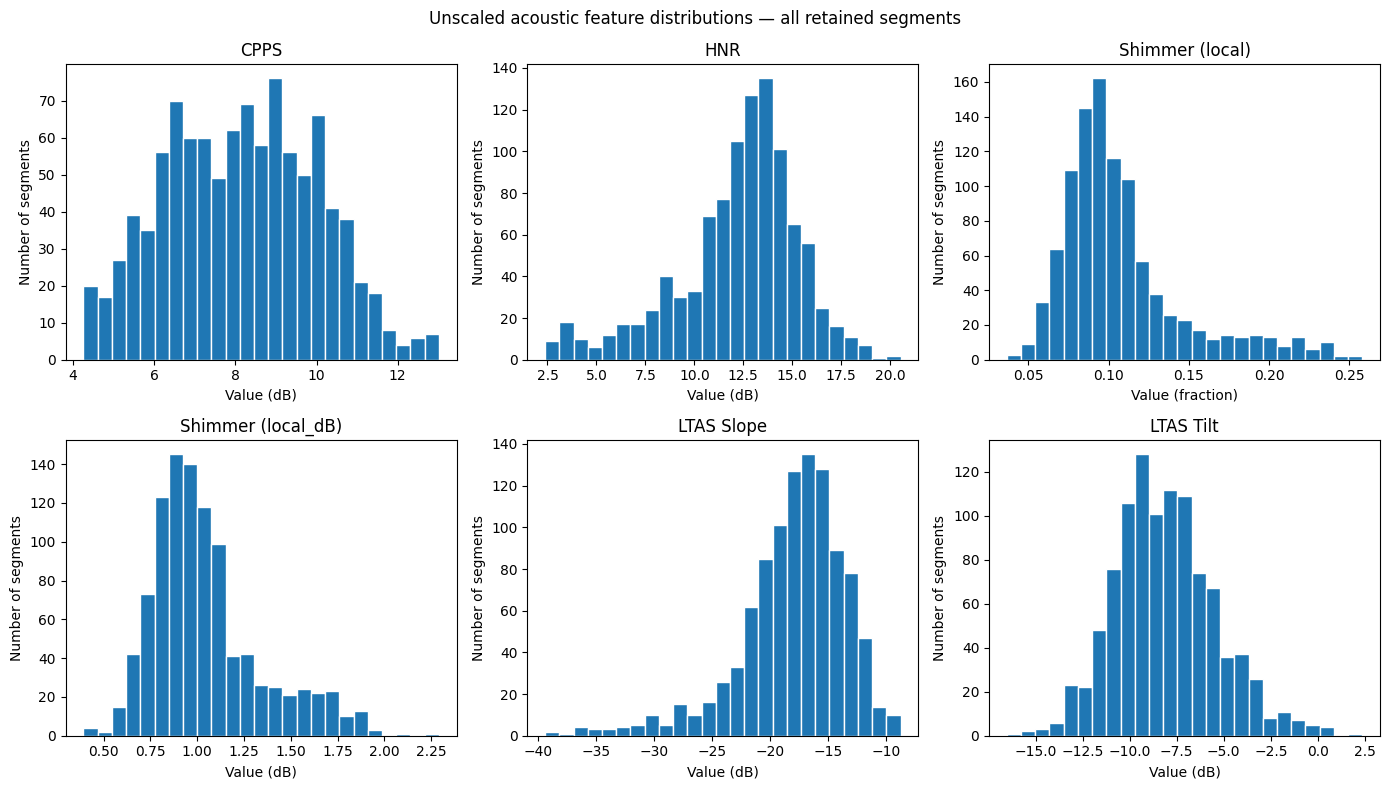

Feature correlations (descriptive only):


,CPPS,HNR,Shimmer (local),Shimmer (local_dB),LTAS Slope,LTAS Tilt
CPPS,1.00,0.60,-0.59,-0.64,0.33,-0.30
HNR,0.60,1.00,-0.87,-0.89,0.12,-0.17
Shimmer (local),-0.59,-0.87,1.00,0.96,-0.29,0.23
Shimmer (local_dB),-0.64,-0.89,0.96,1.00,-0.31,0.24
LTAS Slope,0.33,0.12,-0.29,-0.31,1.00,-0.30
LTAS Tilt,-0.30,-0.17,0.23,0.24,-0.30,1.00


In [5]:
# Inspecting feature distributions without removing unusual observations.
feature_units = ["dB", "dB", "fraction", "dB", "dB", "dB"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feature, unit in zip(axes.flat, FEATURE_COLUMNS, feature_units):
    ax.hist(clean_df[feature], bins=25, edgecolor="white")
    ax.set_title(feature)
    ax.set_xlabel(f"Value ({unit})")
    ax.set_ylabel("Number of segments")
fig.suptitle("Unscaled acoustic feature distributions — all retained segments")
plt.tight_layout()
plt.show()

# Checking potentially redundant measurements; this does not select features.
print("Feature correlations (descriptive only):")
display(clean_df[FEATURE_COLUMNS].corr().round(2))


## 4. Define model inputs, labels, and participant groups
Initially use these six acoustic features:
- CPPS
- HNR
- Shimmer (local)
- Shimmer (local_dB)
- LTAS Slope
- LTAS Tilt

Define `X` as the acoustic features, `y` as `PD` (0 = HC, 1 = PD), and `groups` as `participant_id`. Keep `task` and `segment_id` as metadata; exclude them and participant IDs from model inputs.


In [6]:
# Using the six acoustic features listed in FEATURE_COLUMNS in the setup cell.
# Selecting columns without changing the order of the cleaned rows.
X = clean_df[FEATURE_COLUMNS].copy()
y = clean_df[TARGET_COLUMN].astype(int).copy()
groups = clean_df[GROUP_COLUMN].copy()

# Keeping identifiers separately for tracing predictions and grouping participants.
# These columns will not be passed to the classifier as features.
metadata = clean_df[[GROUP_COLUMN, "task", "segment_id"]].copy()

# Confirming that every feature row matches its label, participant, and metadata.
assert len(X) == len(y) == len(groups) == len(metadata)
assert X.index.equals(y.index), "Feature rows and labels are not aligned."
assert X.index.equals(groups.index), "Feature rows and participant groups are not aligned."
assert X.index.equals(metadata.index), "Feature rows and metadata are not aligned."
assert X.shape[1] == 6, "Expected exactly six acoustic features."
assert not set(metadata.columns).intersection(X.columns), "Metadata must not be model inputs."
assert TARGET_COLUMN not in X.columns, "The target must not be a model input."

print("X shape (segments, features):", X.shape)
print("y shape (labels):", y.shape)
print("groups shape:", groups.shape)
print("Unique participants:", groups.nunique())
print("Labels: 0 = HC, 1 = PD")
print("Row alignment checks passed. Features are still unscaled.")

# Previewing corresponding metadata, labels, and measurements together.
display(pd.concat([metadata, y, X], axis=1).head())


X shape (segments, features): (1013, 6)
y shape (labels): (1013,)
groups shape: (1013,)
Unique participants: 37
Labels: 0 = HC, 1 = PD
Row alignment checks passed. Features are still unscaled.


,participant_id,task,segment_id,PD,CPPS,HNR,Shimmer (local),Shimmer (local_dB),LTAS Slope,LTAS Tilt
0,0,RT,0,0,4.601844,5.988,0.186764,1.611423,-31.491537,-4.685515
1,0,RT,1,0,6.634655,11.073,0.117000,1.441925,-25.671000,-7.142106
2,0,RT,2,0,9.650368,13.924,0.108757,1.074178,-22.987132,-5.577274
3,0,RT,3,0,9.555163,13.267,0.098861,0.994412,-21.863595,-6.280987
4,0,RT,4,0,9.425526,12.861,0.107581,1.050289,-21.375866,-7.686769


## 5. Define participant-separated evaluation
Using the five-fold `StratifiedGroupKFold` with a fixed seed and approximate segment level class balance. Reusing the same folds for the majority-class baseline and SVM.

All RT and SD segments from a participant stay together. we check that train/validation participants do not overlap, both classes occur in every split, and every segment is validated exactly once. These are preliminary cross-validation results, not an independent final test.


In [7]:
# Creating the same reproducible folds for every model.
N_SPLITS = 5
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = list(cv.split(X, y, groups=groups))

fold_rows = []
validation_counts = np.zeros(len(X), dtype=int)
fold_ids = np.full(len(X), -1, dtype=int)
for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
    train_participants = set(groups.iloc[train_idx])
    val_participants = set(groups.iloc[val_idx])
    assert train_participants.isdisjoint(val_participants), "Participant leakage detected."
    assert set(y.iloc[train_idx]) == {0, 1}, "Training fold is missing a class."
    assert set(y.iloc[val_idx]) == {0, 1}, "Validation fold is missing a class."
    assert len(set(train_idx).intersection(val_idx)) == 0
    assert len(train_idx) + len(val_idx) == len(X)
    validation_counts[val_idx] += 1
    fold_ids[val_idx] = fold_number
    fold_rows.append({
        "fold": fold_number,
        "train_participants": len(train_participants),
        "validation_participants": len(val_participants),
        "train_segments": len(train_idx),
        "validation_segments": len(val_idx),
        "train_PD_percent": 100 * y.iloc[train_idx].mean(),
        "validation_HC": int((y.iloc[val_idx] == 0).sum()),
        "validation_PD": int((y.iloc[val_idx] == 1).sum()),
        "validation_PD_percent": 100 * y.iloc[val_idx].mean(),
    })

assert np.all(validation_counts == 1), "Each segment must be validated exactly once."
fold_summary = pd.DataFrame(fold_rows)
display(fold_summary.round(2))
print("All five folds have both classes and no participant overlap.")
print("Every segment appears in exactly one validation fold.")


,fold,train_participants,validation_participants,train_segments,validation_segments,train_PD_percent,validation_HC,validation_PD,validation_PD_percent
0,1,28,9,792,221,41.92,135,86,38.91
1,2,30,7,815,198,40.98,114,84,42.42
2,3,30,7,817,196,41.13,114,82,41.84
3,4,30,7,816,197,41.05,114,83,42.13
4,5,30,7,812,201,41.26,118,83,41.29


All five folds have both classes and no participant overlap.
Every segment appears in exactly one validation fold.


## SVM preprocessing pipeline
Implementing an SVM and a majority class baseline. 




In [8]:
# Defining the pipeline here; fitting happens separately within each fold.
svm_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight=None,
        probability=False,
        tol=0.001,
    )),
])
print(svm_pipeline)


Pipeline(steps=[('scale', StandardScaler()), ('svm', SVC())])


## Training the majority-class baseline
The baseline predicts the most frequent segment label in each training fold. We use the same evaluation function and folds for both models.

Store one out-of-fold prediction per segment. Precision, recall, and F1 treat PD as the positive class; when a model never predicts PD, report precision as zero rather than leaving it undefined.


In [9]:
def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_PD": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall_PD": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1_PD": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }


def evaluate_model(estimator, X, y, folds):
    fold_metrics = []
    predictions = np.full(len(y), -1, dtype=int)
    fitted_models = []
    for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
        # A fresh model also gives the SVM a fresh, training-only scaler.
        model = clone(estimator)
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        if isinstance(model, Pipeline):
            assert model.named_steps["svm"].fit_status_ == 0, "SVM did not converge."
        predicted = model.predict(X.iloc[val_idx])
        predictions[val_idx] = predicted
        fold_metrics.append({
            "fold": fold_number,
            **calculate_metrics(y.iloc[val_idx], predicted),
        })
        fitted_models.append(model)
    assert np.isin(predictions, [0, 1]).all(), "Missing out-of-fold predictions."
    return pd.DataFrame(fold_metrics), predictions, fitted_models


baseline = DummyClassifier(strategy="most_frequent")
baseline_metrics, baseline_predictions, baseline_models = evaluate_model(baseline, X, y, folds)
print("Majority-class baseline: segment-level validation metrics per fold")
display(baseline_metrics.round(3))


Majority-class baseline: segment-level validation metrics per fold


,fold,accuracy,balanced_accuracy,precision_PD,recall_PD,F1_PD
0,1,0.611,0.5,0.0,0.0,0.0
1,2,0.576,0.5,0.0,0.0,0.0
2,3,0.582,0.5,0.0,0.0,0.0
3,4,0.579,0.5,0.0,0.0,0.0
4,5,0.587,0.5,0.0,0.0,0.0


## Train the classification models
### Support Vector Machine (SVM) 
Training the fixed SVM pipeline on the same folds as the baseline. The validation segments belong to participants excluded from that fold's training data.


In [10]:
svm_metrics, svm_predictions, svm_models = evaluate_model(svm_pipeline, X, y, folds)
print("SVM: segment-level validation metrics per fold")
display(svm_metrics.round(3))
print("All five SVM fits converged.")


SVM: segment-level validation metrics per fold


,fold,accuracy,balanced_accuracy,precision_PD,recall_PD,F1_PD
0,1,0.760,0.709,0.837,0.477,0.607
1,2,0.697,0.662,0.750,0.429,0.545
2,3,0.699,0.661,0.745,0.427,0.543
3,4,0.492,0.494,0.416,0.506,0.457
4,5,0.562,0.557,0.473,0.530,0.500


All five SVM fits converged.


### 8.2 Random Forest — planned for later
Not implemented for this progress report.


In [ ]:
# TODO: Define and evaluate a Random Forest using the shared folds.
# TODO: Record the number of trees, tree constraints, and random seed.


### 8.3 k-Nearest Neighbours (k-NN) — planned for later
Not implemented for this progress report.


In [ ]:
# TODO: Define and evaluate a standardized k-NN pipeline using the shared folds.
# TODO: Record the number of neighbours and distance/weighting settings.


## Comparing results and evaluation metrics


Five-fold segment-level results: means and standard deviations


,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_PD_mean,precision_PD_std,recall_PD_mean,recall_PD_std,F1_PD_mean,F1_PD_std
model,,,,,,,,,,
Majority baseline,0.587,0.014,0.500,0.000,0.000,0.000,0.000,0.000,0.00,0.000
SVM (RBF),0.642,0.111,0.617,0.088,0.644,0.187,0.474,0.046,0.53,0.056


Pooled out-of-fold segment-level results


,accuracy,balanced_accuracy,precision_PD,recall_PD,F1_PD
model,,,,,
Majority baseline,0.587,0.500,0.000,0.000,0.000
SVM (RBF),0.645,0.619,0.586,0.474,0.524


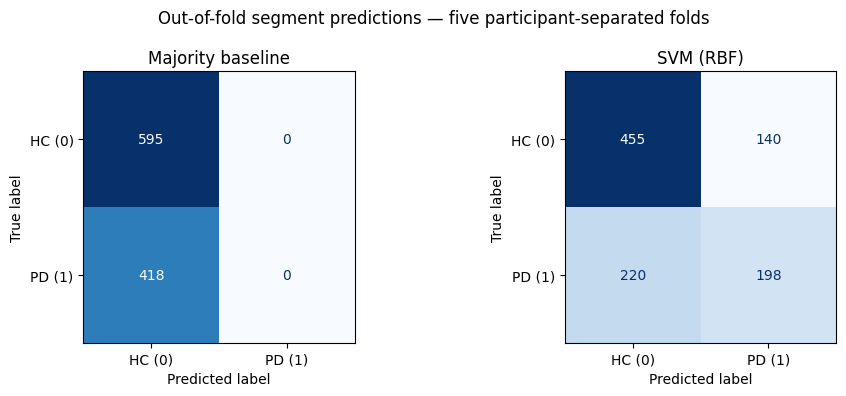

In [11]:
# Comparing means and standard deviations across the five validation folds.
metric_columns = [column for column in svm_metrics.columns if column != "fold"]
summary_rows = []
for name, scores in [("Majority baseline", baseline_metrics), ("SVM (RBF)", svm_metrics)]:
    row = {"model": name}
    for metric in metric_columns:
        row[f"{metric}_mean"] = scores[metric].mean()
        row[f"{metric}_std"] = scores[metric].std(ddof=1)
    summary_rows.append(row)
cv_summary = pd.DataFrame(summary_rows).set_index("model")
print("Five-fold segment-level results: means and standard deviations")
display(cv_summary.round(3))

# Pooled metrics use every segment's held-out prediction exactly once.
pooled_results = pd.DataFrame([
    {"model": "Majority baseline", **calculate_metrics(y, baseline_predictions)},
    {"model": "SVM (RBF)", **calculate_metrics(y, svm_predictions)},
]).set_index("model")
print("Pooled out-of-fold segment-level results")
display(pooled_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, predictions in zip(
    axes, ["Majority baseline", "SVM (RBF)"], [baseline_predictions, svm_predictions]
):
    matrix = confusion_matrix(y, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["HC (0)", "PD (1)"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name)
fig.suptitle("Out-of-fold segment predictions — five participant-separated folds")
plt.tight_layout()
confusion_figure = fig
plt.show()


## 10. Interpret acoustic feature contributions — planned for later
The progress report currently retains all six features without ranking or selection. Held-out feature-importance analysis is a next step. An RBF SVM does not provide one linear coefficient per input feature.

A future analysis may use permutation importance on held-out folds, accounting for correlated measurements. Predictive importance does not establish a causal relationship with PD.


In [ ]:
# TODO: Estimate and visualize feature contributions on held-out data.
# TODO: Discuss consistency across folds and possible redundancy.


## 11. Optional improvements after the initial comparison
Consider limited hyperparameter tuning, feature-selection experiments, or RT-versus-SD comparisons. Any tuning or feature-subset selection must use inner participant-grouped validation, keeping the outer evaluation folds separate.


In [ ]:
# TODO (later): Define a small set of justified improvement experiments.
# TODO (later): Use nested participant-grouped validation if tuning settings.


## 12. Save outputs and write report notes
Save reproducible results in `model/results/svm_progress_report`: fold membership, per-fold metrics, cross-validation summaries, pooled metrics, predictions, confusion matrices, and run settings/package versions.




In [12]:
# Writing results next to this notebook, using the repo path from the setup cell.
import json
import sklearn
from pathlib import Path

RESULTS_FOLDER = Path(DATA_FOLDER).parent / "model" / "results" / "svm_progress_report"
RESULTS_FOLDER.mkdir(parents=True, exist_ok=True)
fold_summary.to_csv(RESULTS_FOLDER / "fold_summary.csv", index=False)
baseline_metrics.to_csv(RESULTS_FOLDER / "baseline_fold_metrics.csv", index=False)
svm_metrics.to_csv(RESULTS_FOLDER / "svm_fold_metrics.csv", index=False)
cv_summary.to_csv(RESULTS_FOLDER / "cv_summary.csv")
pooled_results.to_csv(RESULTS_FOLDER / "pooled_metrics.csv")

# Each row can be traced back to its participant, task, and audio segment.
prediction_rows = metadata.assign(
    true_PD=y.to_numpy(),
    validation_fold=fold_ids,
    baseline_prediction=baseline_predictions,
    svm_prediction=svm_predictions,
)
prediction_rows.to_csv(RESULTS_FOLDER / "out_of_fold_predictions.csv", index=False)
confusion_figure.savefig(RESULTS_FOLDER / "confusion_matrices.png", dpi=180, bbox_inches="tight")

settings = {
    "seed": SEED,
    "features": FEATURE_COLUMNS,
    "segments": len(X),
    "participants": int(groups.nunique()),
    "evaluation": "5-fold StratifiedGroupKFold; segment-level metrics; no tuning or independent test",
    "standardization": "StandardScaler fitted separately on each training fold",
    "svm": svm_pipeline.named_steps["svm"].get_params(),
    "baseline": "DummyClassifier(strategy='most_frequent')",
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit-learn": sklearn.__version__},
}
(RESULTS_FOLDER / "run_settings.json").write_text(json.dumps(settings, indent=2) + "\n")
print("Saved progress-report results to:", RESULTS_FOLDER)


Saved progress-report results to: /Users/mominah/Desktop/COMPSCI 4AL3/Project/pd-speech-detection/model/results/svm_progress_report
